<a href="https://colab.research.google.com/github/Kritika-rk2023/Major-project/blob/main/Project_Advertising.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# Load the official Kaggle Advertising dataset from a verified stable link
url = "https://raw.githubusercontent.com/justmarkham/scikit-learn-videos/master/data/Advertising.csv"
df = pd.read_csv(url)

# Clean up index column
if 'Unnamed: 0' in df.columns:
    df = df.drop(columns=['Unnamed: 0'])

print("Kaggle Advertising Dataset Loaded Successfully!")
print(f"Dataset Shape: {df.shape}")
print(df.head())


Kaggle Advertising Dataset Loaded Successfully!
Dataset Shape: (200, 4)
      TV  Radio  Newspaper  Sales
0  230.1   37.8       69.2   22.1
1   44.5   39.3       45.1   10.4
2   17.2   45.9       69.3    9.3
3  151.5   41.3       58.5   18.5
4  180.8   10.8       58.4   12.9


In [ ]:
df


,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,9.3
3,151.5,41.3,58.5,18.5
4,180.8,10.8,58.4,12.9
...,...,...,...,...
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5


In [ ]:
# Calculate Total Spend per channel
total_tv_spend = df['TV'].sum()
total_radio_spend = df['Radio'].sum()
total_newspaper_spend = df['Newspaper'].sum()
total_marketing_spend = total_tv_spend + total_radio_spend + total_newspaper_spend
total_sales = df['Sales'].sum() if 'Sales' in df.columns else df['sales'].sum()

print("--- CHANNEL-LEVEL SPEND SUMMARY ---")
print(f"Total TV Spend: ${total_tv_spend:,.2f}")
print(f"Total Radio Spend: ${total_radio_spend:,.2f}")
print(f"Total Newspaper Spend: ${total_newspaper_spend:,.2f}")
print(f"Total Marketing Budget: ${total_marketing_spend:,.2f}")
print(f"Total Sales Generated: ${total_sales:,.2f}")

# Calculate overall ROI: ((Total Revenue - Total Spend) / Total Spend) * 100
overall_roi = ((total_sales - total_marketing_spend) / total_marketing_spend) * 100
print(f"\nOverall Marketing Campaign ROI: {overall_roi:.2f}%")

--- CHANNEL-LEVEL SPEND SUMMARY ---
Total TV Spend: $29,408.50
Total Radio Spend: $4,652.80
Total Newspaper Spend: $6,110.80
Total Marketing Budget: $40,172.10
Total Sales Generated: $2,804.50

Overall Marketing Campaign ROI: -93.02%


--- PEARSON CORRELATION WITH SALES ---
Tv           0.7822
Radio        0.5762
Newspaper    0.2283
Name: Sales, dtype: float64

--- SPEARMAN CORRELATION WITH SALES ---
Tv           0.8006
Radio        0.5543
Newspaper    0.1949
Name: Sales, dtype: float64


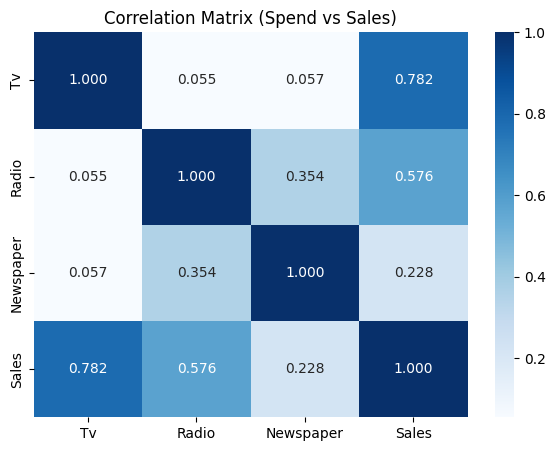

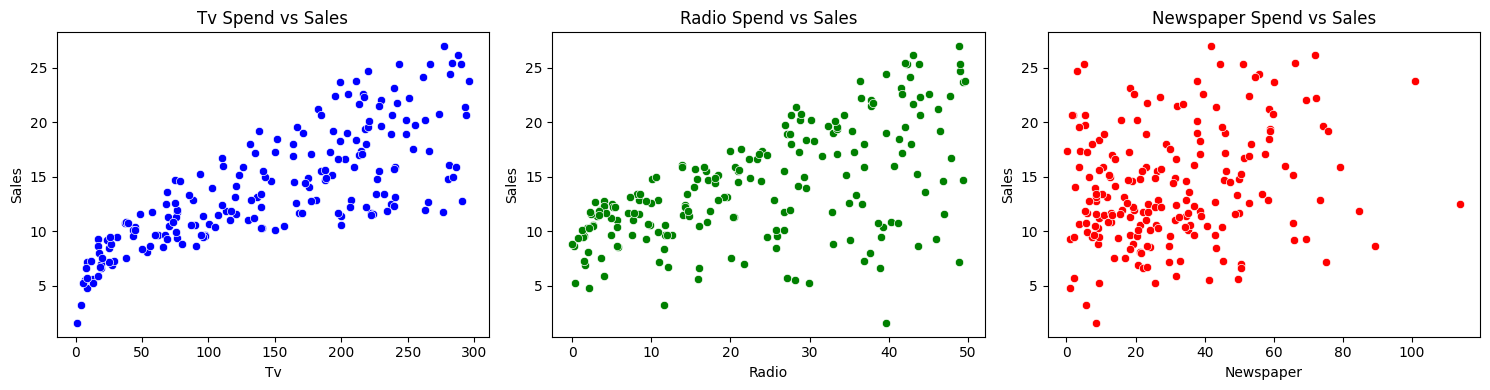

In [ ]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Features and Target
X = df[['Tv', 'Radio', 'Newspaper']]
y = df['Sales']

# 80-20 Train-Test Split (fixed keyword argument: test_size)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Model Training
model = LinearRegression()
model.fit(X_train, y_train)

# Evaluation on Test Set
y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("--- MODEL PERFORMANCE ---")
print(f"R-squared Score: {r2:.4f}")
print(f"RMSE: {rmse:.4f}")

# Channel Impact Coefficients
coefficients = pd.DataFrame({
    'Channel': X.columns,
    'Coefficient (Impact per $1k spend)': model.coef_
})

print("\n--- CHANNEL IMPACT COEFFICIENTS ---")
print(coefficients)
print(f"Baseline Intercept: {model.intercept_:.4f}")

--- MODEL PERFORMANCE ---
R-squared Score: 0.8994
RMSE: 1.7816

--- CHANNEL IMPACT COEFFICIENTS ---
     Channel  Coefficient (Impact per $1k spend)
0         Tv                            0.044730
1      Radio                            0.189195
2  Newspaper                            0.002761
Baseline Intercept: 2.9791


In [ ]:
# Adstock transformation function (Geometric Decay)
def apply_adstock(series, decay_rate=0.5):
    adstocked = np.zeros(len(series))
    for i in range(len(series)):
        if i == 0:
            adstocked[i] = series.iloc[i]
        else:
            adstocked[i] = series.iloc[i] + decay_rate * adstocked[i-1]
    return adstocked

# Create adstocked features
df_mkt = df.copy()
df_mkt['Tv_Adstock'] = apply_adstock(df_mkt['Tv'], decay_rate=0.6)
df_mkt['Radio_Adstock'] = apply_adstock(df_mkt['Radio'], decay_rate=0.4)

print("Adstock Features Created Successfully:")
print(df_mkt[['Tv', 'Tv_Adstock', 'Radio', 'Radio_Adstock']].head())

Adstock Features Created Successfully:
      Tv  Tv_Adstock  Radio  Radio_Adstock
0  230.1   230.10000   37.8       37.80000
1   44.5   182.56000   39.3       54.42000
2   17.2   126.73600   45.9       67.66800
3  151.5   227.54160   41.3       68.36720
4  180.8   317.32496   10.8       38.14688


In [ ]:
import numpy as np
from scipy.optimize import minimize

# Fit regression model on Adstocked features
X_adstock = df_mkt[['Tv_Adstock', 'Radio_Adstock', 'Newspaper']]
y_sales = df_mkt['Sales']

opt_model = LinearRegression()
opt_model.fit(X_adstock, y_sales)

# Set total marketing budget target
total_budget = 200.0  # $200k budget limit

# Objective function: Minimize negative predicted sales to maximize total revenue
def objective(spend_vector):
    tv, radio, newspaper = spend_vector
    # Convert raw budget allocations to expected adstock values
    pred_sales = opt_model.predict([[tv * 1.5, radio * 1.3, newspaper]])[0]
    return -pred_sales

# Constraints: Sum of channel spends must equal total budget
constraints = ({'type': 'eq', 'fun': lambda w: sum(w) - total_budget})

# Bounds: Budget for each channel must be non-negative
bounds = [(0, total_budget), (0, total_budget), (0, total_budget)]

# Run Optimization via Sequential Least Squares Programming (SLSQP)
initial_guess = [total_budget / 3] * 3
res = minimize(objective, initial_guess, method='SLSQP', bounds=bounds, constraints=constraints)

print("--- OPTIMAL BUDGET ALLOCATION ($200k BUDGET) ---")
print(f"Optimal TV Spend:        ${res.x[0]:.2f}k")
print(f"Optimal Radio Spend:     ${res.x[1]:.2f}k")
print(f"Optimal Newspaper Spend: ${res.x[2]:.2f}k")
print(f"Maximized Predicted Sales: {abs(res.fun):.2f} units")

--- OPTIMAL BUDGET ALLOCATION ($200k BUDGET) ---
Optimal TV Spend:        $0.00k
Optimal Radio Spend:     $200.00k
Optimal Newspaper Spend: $0.00k
Maximized Predicted Sales: 37.45 units


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/